# 08 — Prever views **antes** de postar

1. **Inventário:** quais colunas são conhecidas antes da publicação (e quais só existem depois).
2. **Checagem dos dados pré-publicação:** tipo, categoria, duração, quem posta, patrocínio.
3. **"Quem posta" vira histórico do creator:** média e último resultado dos posts **anteriores** (sem olhar o futuro).
4. **Validação temporal:** treina no passado (~80% iniciais do período) e testa nos posts mais recentes, como numa previsão real.
5. **Blocos acumulados:** conteúdo → + quem posta → + patrocínio → + horário → + audiência (LightGBM e CatBoost).
6. **Controle positivo:** se "quem posta" importasse, o método perceberia?

In [1]:
# Setup: make solution/src importable and load the posts with derived features.
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "solution" / "src").exists())
sys.path.insert(0, str(ROOT / "solution" / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from social_insights import data, top_performers as tp, clustering as cl, drivers as dr, audience as au, nlp, validation as va, plots

plots.apply_style()
pd.set_option("display.float_format", "{:.4f}".format)
df = data.load_posts(ROOT)
print(f"{len(df):,} posts")

from social_insights import views_forecast as vf

52,214 posts


## 1. Inventário: o que se sabe antes de postar

In [2]:
inv = vf.inventory()
display(Markdown(f"**{int(inv['conhecido antes de postar'].sum())} colunas conhecidas antes** · {int((~inv['conhecido antes de postar']).sum())} só depois ou sem uso"))
inv

**18 colunas conhecidas antes** · 9 só depois ou sem uso

,conhecido antes de postar,bloco,observação
coluna,,,
audience_gender_distribution,True,audiência,perfil histórico da audiência do creator
audience_age_distribution,True,audiência,idem
audience_location,True,audiência,idem
platform,True,conteúdo,escolhido na publicação
content_type,True,conteúdo,vídeo / imagem / texto / misto
content_category,True,conteúdo,tema
language,True,conteúdo,idioma do post
content_length,True,conteúdo,duração (s) ou nº de palavras; ATENÇÃO: 10–599...
content_description,True,conteúdo,legenda (texto livre); usada como nº de palavras


## 2. Checagem dos dados pré-publicação

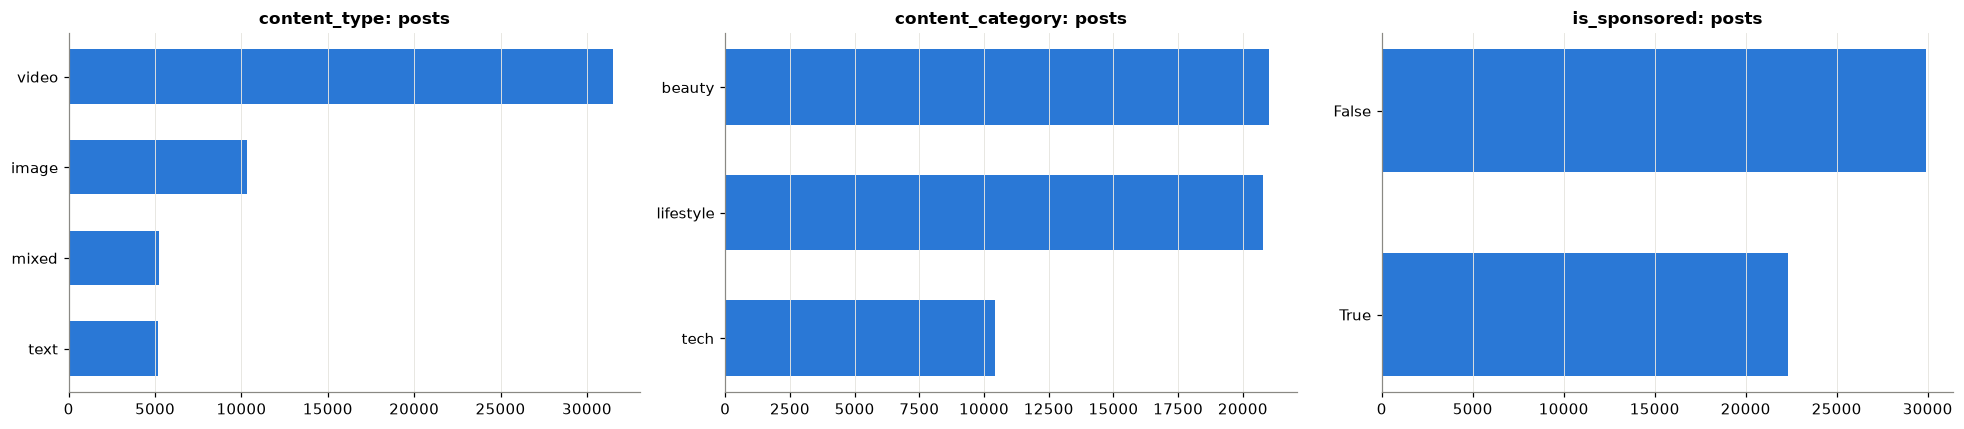

**Duração (`content_length`) por formato:** deveria ser segundos para vídeo e palavras para texto, mas a faixa é a mesma em todos

,count,min,50%,max
content_type,,,,
image,10303.0000,10.0000,173.0000,599.0000
mixed,5213.0000,10.0000,175.0000,599.0000
text,5198.0000,10.0000,174.0000,599.0000
video,31500.0000,10.0000,174.0000,599.0000


**Quem posta:**

,creators,posts por creator (mediana),nomes por creator_id (mediana),seguidores distintos por creator (mediana)
0,5000,10.0000,10.0000,10.0000


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ["content_type", "content_category", "is_sponsored"]):
    counts = df[col].astype(str).value_counts().sort_values()
    ax.barh(counts.index, counts.values, color=plots.BLUE, height=0.6)
    ax.set_title(f"{col}: posts"); ax.grid(axis="y", visible=False)
fig.tight_layout(); plt.show()

length = df.groupby("content_type")["content_length"].describe()[["count", "min", "50%", "max"]]
display(Markdown("**Duração (`content_length`) por formato:** deveria ser segundos para vídeo e palavras para texto, mas a faixa é a mesma em todos"))
display(length)
display(Markdown("**Quem posta:**"))
pd.DataFrame({"creators": [df.creator_id.nunique()], "posts por creator (mediana)": [df.creator_id.value_counts().median()],
              "nomes por creator_id (mediana)": [df.groupby("creator_id").creator_name.nunique().median()],
              "seguidores distintos por creator (mediana)": [df.groupby("creator_id").follower_count.nunique().median()]})

**Leitura:**
- `content_length` vai de 10 a 599 em **todos** os formatos, inclusive imagem. É usado no modelo, mas não representa "tamanho do vídeo" de forma confiável.
- `creator_id` existe (5 mil creators, ~10 posts cada), mas o **nome e o nº de seguidores mudam a cada post**. Por isso "quem posta" entra como **histórico de resultados** do creator_id, e o seguidor como valor do momento.

## 3. Quem posta: creators mantêm o nível?

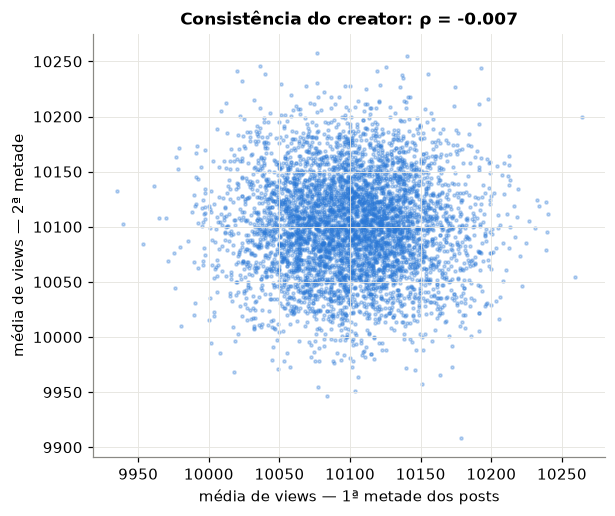

In [4]:
cons = vf.creator_consistency(df)
data_sorted = df.sort_values("post_date")
rank = data_sorted.groupby("creator_id").cumcount(); size = data_sorted.groupby("creator_id")["views"].transform("size")
first = data_sorted[rank < size / 2].groupby("creator_id")["views"].mean()
second = data_sorted[rank >= size / 2].groupby("creator_id")["views"].mean()
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(first, second, s=4, alpha=0.3, color=plots.BLUE)
ax.set_xlabel("média de views — 1ª metade dos posts"); ax.set_ylabel("média de views — 2ª metade")
ax.set_title(f"Consistência do creator: ρ = {cons['ρ (1ª metade × 2ª metade)']:.3f}")
plt.show()

**Leitura:** a média de um creator na 1ª metade dos posts **não diz nada** sobre a 2ª (ρ ≈ 0, nuvem redonda). Nenhum creator é consistentemente forte ou fraco.
Em dados reais, esse ρ costuma ser alto (o creator tem audiência própria). É o teste mais direto de "quem postou importa?".

## 4. Previsão com validação temporal

In [5]:
history = vf.add_creator_history(df)
tr, te, cutoff = vf.temporal_split(history)
display(Markdown(f"Treino: posts até **{cutoff.date()}** ({len(tr):,}) · Teste: posts depois ({len(te):,})"))
evaluation = vf.evaluate(df)
evaluation.style.format({"R² treino": "{:.4f}", "R²": "{:.4f}", "MAE (views)": "{:.1f}", "erro médio (%)": "{:.3f}",
                         "p (melhor que média)": "{:.3f}", "ganho MAE vs. média (%)": "{:+.2f}"}, na_rep="—")

Treino: posts até **2024-12-31** (41,771) · Teste: posts depois (10,443)

,abordagem,modelo,R² treino,R²,MAE (views),erro médio (%),p (melhor que média),ganho MAE vs. média (%),supera a média
0,baseline: média histórica,—,0.0000,-0.0000,79.9,0.791,—,+0.00,False
1,baseline: média passada do creator,—,—,-0.1204,84.5,0.837,1.000,-5.81,False
2,1. conteúdo,LightGBM,0.0556,-0.0053,80.1,0.793,0.979,-0.22,False
3,1. conteúdo,CatBoost,0.0062,-0.0009,79.9,0.791,0.532,-0.02,False
4,2. + quem posta,LightGBM,0.0892,-0.0072,80.2,0.794,1.000,-0.42,False
5,2. + quem posta,CatBoost,0.0232,-0.0035,80.0,0.793,0.990,-0.20,False
6,3. + patrocínio,LightGBM,0.0922,-0.0082,80.2,0.794,1.000,-0.41,False
7,3. + patrocínio,CatBoost,0.0179,-0.0026,80.0,0.792,0.999,-0.16,False
8,4. + horário,LightGBM,0.0991,-0.0075,80.2,0.794,1.000,-0.42,False
9,4. + horário,CatBoost,0.0200,-0.0023,80.0,0.792,0.993,-0.13,False


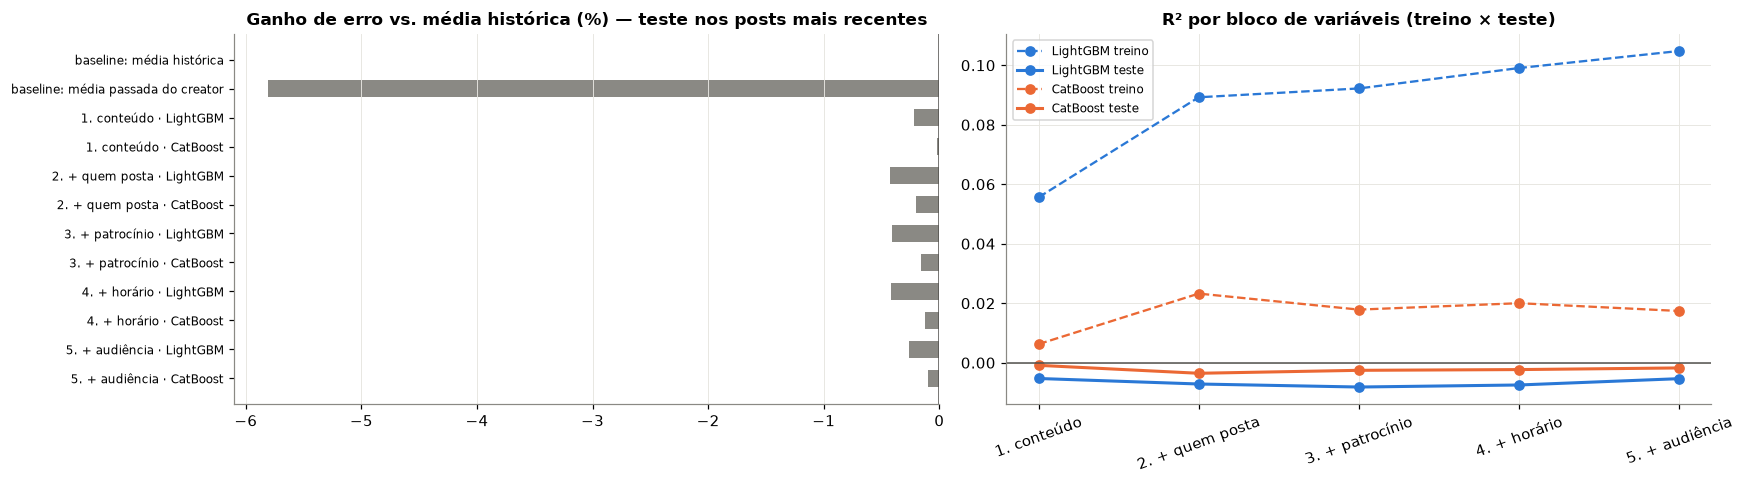

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
ev = evaluation.copy(); ev["rótulo"] = ev["abordagem"] + np.where(ev["modelo"] == "—", "", " · " + ev["modelo"])
y = np.arange(len(ev))[::-1]
axes[0].barh(y, ev["ganho MAE vs. média (%)"], color=[plots.BLUE if s else plots.GRAY for s in ev["supera a média"]], height=0.6)
axes[0].axvline(0, color=plots.INK, linewidth=1); axes[0].set_yticks(y, ev["rótulo"], fontsize=8)
axes[0].set_title("Ganho de erro vs. média histórica (%) — teste nos posts mais recentes"); axes[0].grid(axis="y", visible=False)
sub = ev[ev.modelo != "—"]
for name, color in [("LightGBM", plots.BLUE), ("CatBoost", plots.ORANGE)]:
    s = sub[sub.modelo == name]
    axes[1].plot(s["abordagem"], s["R² treino"], "o--", color=color, label=f"{name} treino")
    axes[1].plot(s["abordagem"], s["R²"], "o-", color=color, linewidth=2, label=f"{name} teste")
axes[1].axhline(0, color=plots.INK, linewidth=1); axes[1].set_title("R² por bloco de variáveis (treino × teste)")
axes[1].tick_params(axis="x", rotation=20); axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

**Leitura:**
- **Nenhum bloco supera a média histórica** nos posts mais recentes. Acrescentar quem posta, patrocínio, horário ou audiência não reduz o erro.
- **Usar a média passada do creator piora** (+5,8% de erro), porque o histórico dele é ruído e não um sinal.
- O LightGBM "aprende" cada vez mais no treino (R² até ~0,10) e nada no teste: **decora**.
- O erro típico já é de ~0,8% (~80 views), simplesmente porque as views quase não variam.

## 5. Controle positivo: e se quem posta importasse?

In [7]:
planted = va.inject_creator_effect(df, "views", relative_sd=0.03)          # each creator with a persistent level (±3%)
planted = va.inject_uplift(planted, va.demo_segment(planted), "views", 0.03)  # + content effect: TikTok × video × tech
display(Markdown(f"Consistência do creator com o efeito plantado: ρ = **{vf.creator_consistency(planted)['ρ (1ª metade × 2ª metade)']:.2f}**"))
ev_planted = vf.evaluate(planted, models=("LightGBM",))
ev_planted[["abordagem", "modelo", "R²", "erro médio (%)", "ganho MAE vs. média (%)", "supera a média"]].round(4)

Consistência do creator com o efeito plantado: ρ = **0.97**

,abordagem,modelo,R²,erro médio (%),ganho MAE vs. média (%),supera a média
0,baseline: média histórica,—,-0.0000,2.5342,0.0000,False
1,baseline: média passada do creator,—,0.8629,0.8990,64.4083,True
2,1. conteúdo,LightGBM,0.0141,2.5179,0.6798,False
3,2. + quem posta,LightGBM,0.8822,0.8647,65.8037,True
4,3. + patrocínio,LightGBM,0.8819,0.8663,65.7407,True
5,4. + horário,LightGBM,0.8815,0.8676,65.6908,True
6,5. + audiência,LightGBM,0.8815,0.8677,65.6853,True


**Leitura:** quando cada creator tem um nível próprio, o bloco **"+ quem posta"** salta para R² ≈ 0,88 e erra ~66% menos que a média. O histórico do creator vira o principal preditor, como esperado.
**Logo, a ausência de previsão nos dados originais é real:** o método enxergaria "quem posta" e "o que posta" se isso existisse.

## 6. Previsor pronto para uso

In [8]:
forecaster = vf.ViewsForecaster.train(df, evaluation)
planned = pd.DataFrame([
    {"platform": "TikTok", "content_type": "video", "content_category": "tech", "language": "English", "content_length": 45,
     "caption_words": 15, "n_hashtags": 3, "follower_count": 25_000, "is_sponsored": True, "sponsor_category": "electronics",
     "disclosure_type": "explicit", "disclosure_location": "caption", "weekday": "Friday", "hour": 19,
     "audience_gender_distribution": "male", "audience_age_distribution": "19-25", "audience_location": "USA",
     **vf.creator_snapshot(df, "creator_586")},
])
display(Markdown(f"Modelo adotado nos dados originais: **{forecaster.model_name}**"))
display(forecaster.predict(planned))
planted_forecaster = vf.ViewsForecaster.train(planted, ev_planted)
planned_planted = planned.assign(**vf.creator_snapshot(planted, "creator_586"))
display(Markdown(f"Com efeito plantado: **{planted_forecaster.model_name}**"))
planted_forecaster.predict(planned_planted)

Modelo adotado nos dados originais: **média histórica**

,views previstas,intervalo 90% inf,intervalo 90% sup,modelo
0,10100.2833,9935.0087,10267.0087,média histórica


Com efeito plantado: **LightGBM (2. + quem posta)**

,views previstas,intervalo 90% inf,intervalo 90% sup,modelo
0,10395.5943,10219.8227,10583.6290,LightGBM (2. + quem posta)


**Uso:** `.venv/bin/python solution/cli/predict_views.py --creator_id creator_586 --platform TikTok --content_type video --content_category tech --content_length 45`

## 7. Conclusões
1. **Dá para saber antes de postar:** plataforma, formato, categoria, idioma, duração, legenda/hashtags (como contagem), creator (via histórico), seguidores, patrocínio/disclosure, horário e audiência do creator. O resto (views, likes, shares, comentários) é resultado.
2. **Nenhuma combinação desses dados prevê as views** melhor que a média histórica (10.100 ± ~165 views, intervalo de 90%), nem com validação temporal e modelos de boosting.
3. **"Quem posta" não importa neste dataset:** creators não mantêm o nível (ρ ≈ 0) e o histórico deles piora a previsão.
4. **Qualidade:** `content_length` não distingue formatos, e nome/seguidores do creator mudam a cada post.
5. **O previsor está pronto e é honesto:** usa a média e avisa enquanto nada ajudar. Com dados reais (ou com o efeito plantado), adota sozinho o modelo com histórico do creator.